# Four-Class White Blood Cell Classification

**Setup:** Select Runtime → Change runtime type → T4 GPU, then run the cells in order.

**Research question:** Does fine-tuning ResNet18’s final residual block improve classification compared with a frozen backbone, and does light augmentation help?

We use a **four-class subset of BloodMNIST+ (64×64), derived from Barcelona PBC**. Original train/validation/test assignments are retained after exact-image deduplication. Images are resized to **224×224**.

**Experiments:**
- **A:** Frozen backbone + augmentation.
- **B:** Fine-tune `layer4` and classification head + augmentation.
- **C:** Fine-tune `layer4` and classification head without augmentation.

Each condition uses seeds **42 and 2026**. Checkpoints and the final method are selected using **validation macro-F1**. All predefined conditions are evaluated on the test set.

**Limitations:** Upsampling cannot restore lost detail. Patient independence and cross-hospital generalization remain unverified. This is cell classification, not disease diagnosis.

In [1]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                       'medmnist==3.0.2', 'scikit-learn', 'pandas',
                       'matplotlib', 'pillow', 'tqdm'])


0

## 1. Configuration and persistent output
首次运行允许连接自己的 Google Drive。数据与训练在 Colab 本地完成；结果、最佳权重和日志存到 Drive。
若不连接 Drive，将 `SAVE_TO_DRIVE=False`，但断线前必须下载输出 ZIP。恢复时使用相同配置；完整实验会跳过，未完成实验从头重跑。


In [2]:
import os, json, random, time, hashlib, platform, shutil, gc, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms as T
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)
import medmnist
from tqdm.auto import tqdm
from IPython.display import display

SAVE_TO_DRIVE = True
SEEDS = [42, 2026]
MAX_EPOCHS = 8
PATIENCE = 3
BATCH_SIZE = 64
NUM_WORKERS = 2
INPUT_SIZE = 224
DATA_SIZE = 64
CLASSES = ['eosinophil', 'lymphocyte', 'monocyte', 'neutrophil']
EXPERIMENTS = {
    'A_frozen_aug': {'finetune': False, 'augment': True},
    'B_layer4_aug': {'finetune': True, 'augment': True},
    'C_layer4_noaug': {'finetune': True, 'augment': False},
}
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT = Path('/content/drive/MyDrive/MD6329_WBC_ResNet18_v2_dedup')
else:
    OUT = Path('/content/MD6329_WBC_ResNet18_v2_dedup')
OUT.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path('/content/wbc_data')
DATA_ROOT.mkdir(exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type == 'cuda', '请选择 T4 GPU，再重新运行；完整训练不建议在 CPU 上进行。'
torch.set_num_threads(2)
AMP = True

CONFIG = dict(dataset='BloodMNIST+ four-class subset', data_size=DATA_SIZE,
    input_size=INPUT_SIZE, seeds=SEEDS, max_epochs=MAX_EPOCHS, patience=PATIENCE,
    batch_size=BATCH_SIZE, classes=CLASSES, experiments=EXPERIMENTS,
    head_lr=1e-3, backbone_lr=1e-4, optimizer='AdamW', weight_decay=1e-4,
    selection='maximum validation macro-F1; earliest epoch breaks ties',
    split='official image-level split filtered by exact hash; train > val > test; conflicting labels excluded',
    augmentation='horizontal/vertical flips p=0.5; rotation +/-15 degrees',
    frozen_batchnorm='running statistics fixed outside unfrozen layer4',
    source='https://medmnist.com/', source_pbc='https://data.mendeley.com/datasets/snkd93bnjr/1')
config_path = OUT/'config.json'
if config_path.exists():
    old = json.loads(config_path.read_text())
    assert old == CONFIG, '配置已改变。请使用新的 OUT 文件夹，避免混用结果。'
else:
    config_path.write_text(json.dumps(CONFIG, indent=2))
versions = dict(python=sys.version, torch=torch.__version__,
    torchvision=torchvision.__version__, medmnist=medmnist.__version__,
    numpy=np.__version__, gpu=torch.cuda.get_device_name(0))
(OUT/'environment.json').write_text(json.dumps(versions, indent=2))
print('Output:', OUT, '\nGPU:', versions['gpu'])

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    seed = torch.initial_seed() % 2**32
    np.random.seed(seed); random.seed(seed)


Mounted at /content/drive
Output: /content/drive/MyDrive/MD6329_WBC_ResNet18_v2_dedup 
GPU: Tesla T4


## 2. Automatic Download, Class Mapping and Split Audit

Automatically download the data, read published label names, select four classes, and report per-split counts. `source_index` is an image index within its original split, not a patient ID.

Save pixel-level hashes to detect exact duplicates within/across splits. Keep one copy by **train → val → test** priority; exclude all copies with conflicting labels. Save removal records, before/after manifests, and final counts.

**Deduplication neither establishes patient independence nor excludes near-duplicates.** Results describe a filtered four-class subset, not the unmodified official benchmark.

Original labels: {'0': 'basophil', '1': 'eosinophil', '2': 'erythroblast', '3': 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)', '4': 'lymphocyte', '5': 'monocyte', '6': 'neutrophil', '7': 'platelet'}


100%|██████████| 156M/156M [01:59<00:00, 1.31MB/s]


split,test,train,val
class_name,,,
eosinophil,624,2181,312
lymphocyte,243,849,122
monocyte,284,993,143
neutrophil,666,2330,333


Removed exact duplicate/conflicting rows: 9
Counts AFTER deduplication (use these in the report):


split,train,val,test
class_name,,,
eosinophil,2178,310,622
lymphocyte,849,122,243
monocyte,992,143,284
neutrophil,2330,333,665


Exact cross-split duplicate audit passed. Patient independence remains unverified.


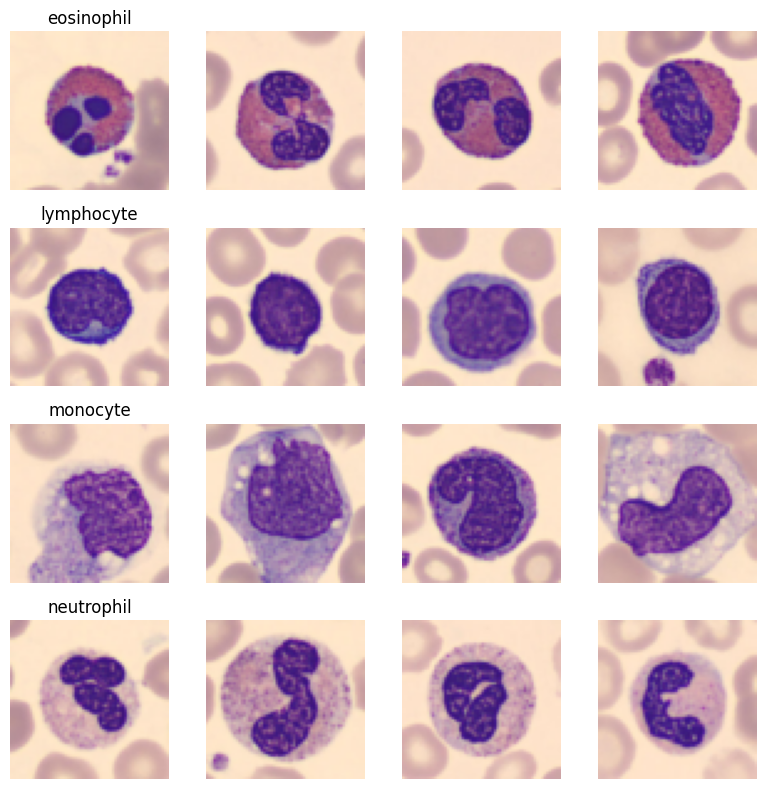

In [3]:
INFO = medmnist.INFO['bloodmnist']
print('Original labels:', INFO['label'])
label_lookup = {str(v).strip().lower(): int(k) for k,v in INFO['label'].items()}
assert set(CLASSES).issubset(label_lookup), label_lookup
old_to_new = {label_lookup[name]: i for i,name in enumerate(CLASSES)}
DATA, manifest = {}, []
for split in ['train', 'val', 'test']:
    raw = medmnist.BloodMNIST(split=split, root=str(DATA_ROOT),
                             size=DATA_SIZE, download=True)
    y_original = raw.labels.reshape(-1)
    ids = np.flatnonzero(np.isin(y_original, list(old_to_new)))
    images = raw.imgs[ids]
    labels = np.array([old_to_new[int(v)] for v in y_original[ids]], dtype=np.int64)
    DATA[split] = {'images':images, 'labels':labels, 'source_index':ids}
    for i, (im, label, original_index) in enumerate(zip(images, labels, ids)):
        manifest.append(dict(split=split, subset_index=i, source_index=int(original_index),
            label=int(label), class_name=CLASSES[int(label)],
            sha256=hashlib.sha256(np.ascontiguousarray(im).tobytes()).hexdigest()))
    del raw
manifest = pd.DataFrame(manifest)
manifest.to_csv(OUT/'split_manifest.csv', index=False)
counts = pd.crosstab(manifest.class_name, manifest.split).reindex(CLASSES)
counts.to_csv(OUT/'class_counts.csv')
display(counts)
cross_split = manifest.groupby('sha256').split.nunique()
leak_hashes = cross_split[cross_split > 1].index
audit = dict(exact_cross_split_hashes=len(leak_hashes),
    exact_duplicate_rows_within_or_across=len(manifest)-manifest.sha256.nunique(),
    patient_ids_available=False, near_duplicate_audit=False,
    limitation='Image-level evaluation only. Exact hashes do not establish patient independence.')
(OUT/'data_audit.json').write_text(json.dumps(audit, indent=2))
manifest[manifest.sha256.isin(leak_hashes)].to_csv(OUT/'cross_split_duplicates.csv', index=False)

# Remove exact duplicates before training, using fixed train > val > test priority.
# Contradictory labels: remove all copies rather than choose a label.
def deduplicate_manifest(frame):
    conflicts = frame.groupby('sha256').label.nunique()
    conflicts = set(conflicts[conflicts > 1].index)
    ranked = frame.assign(_priority=frame.split.map({'train':0,'val':1,'test':2}))
    ranked = ranked.sort_values(['_priority','source_index'],kind='stable')
    bad = ranked.sha256.isin(conflicts)
    copies = (~bad) & ranked.duplicated('sha256',keep='first')
    removed = ranked[bad|copies].copy()
    removed['removal_reason'] = np.where(removed.sha256.isin(conflicts),
        'conflicting_labels_all_copies_removed','exact_duplicate_train_val_test_priority')
    kept = ranked[~(bad|copies)].copy()
    return kept.drop(columns='_priority'), removed.drop(columns='_priority'),len(conflicts)

manifest.to_csv(OUT/'split_manifest_before_dedup.csv',index=False)
kept, removed, conflict_count = deduplicate_manifest(manifest)
removed.to_csv(OUT/'removed_exact_duplicates.csv',index=False)
clean_frames=[]
for split in ['train','val','test']:
    part=kept[kept.split==split].sort_values('subset_index').copy()
    take=part.subset_index.to_numpy(dtype=int)
    DATA[split]={key:values[take] for key,values in DATA[split].items()}
    part['subset_index']=np.arange(len(part))
    clean_frames.append(part)
manifest=pd.concat(clean_frames,ignore_index=True)
assert manifest.sha256.is_unique, '去重检查未通过。'
counts=pd.crosstab(manifest.class_name,manifest.split).reindex(index=CLASSES,columns=['train','val','test']).fillna(0).astype(int)
assert (counts>0).all().all(), '去重后某个划分缺少一个类别，请先检查数据。'
manifest.to_csv(OUT/'split_manifest.csv',index=False)
counts.to_csv(OUT/'class_counts.csv')
audit.update(exact_cross_split_hashes_before=int(len(leak_hashes)),
    exact_cross_split_hashes=0, removed_rows=int(len(removed)),
    conflicting_label_hashes=int(conflict_count),
    split_policy='Official image-level split filtered by exact hash; train > val > test; conflicting labels removed in all splits.',
    evaluation_limitation='Modified four-class image-level benchmark, not the unmodified official benchmark. Near duplicates and patient overlap remain unverified.')
(OUT/'data_audit.json').write_text(json.dumps(audit,indent=2))
print('Removed exact duplicate/conflicting rows:',len(removed))
print('Counts AFTER deduplication (use these in the report):')
display(counts)

print('Exact cross-split duplicate audit passed. Patient independence remains unverified.')
fig, axes = plt.subplots(4,4,figsize=(8,8))
for c in range(4):
    ids = np.flatnonzero(DATA['train']['labels']==c)[:4]
    for j,idx in enumerate(ids):
        axes[c,j].imshow(DATA['train']['images'][idx]); axes[c,j].axis('off')
        if j==0: axes[c,j].set_title(CLASSES[c])
plt.tight_layout(); plt.savefig(OUT/'training_examples.png',dpi=160); plt.show()


## 3. Dataset, Frozen BatchNorm and Evaluation Helpers

All conditions start independently from the same ImageNet weights and identical randomly initialized classification heads within each seed. **B/C do not continue training from A.**

BatchNorm running statistics remain fixed in frozen modules; those in `layer4` update when it is unfrozen. All conditions use the same epoch limit and early-stopping rule.

In [4]:
MEAN, STD = [0.485,0.456,0.406], [0.229,0.224,0.225]
def make_transform(augment=False):
    ops = [T.Resize((INPUT_SIZE,INPUT_SIZE), antialias=True)]
    if augment:
        ops += [T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                T.RandomRotation(15, fill=(240,240,240))]
    return T.Compose(ops+[T.ToTensor(),T.Normalize(MEAN,STD)])

class CellDataset(Dataset):
    def __init__(self, split, augment=False):
        self.data=DATA[split]; self.tf=make_transform(augment)
    def __len__(self): return len(self.data['labels'])
    def __getitem__(self, i):
        return self.tf(Image.fromarray(self.data['images'][i])), int(self.data['labels'][i]), i

def loader(split, augment=False, seed=42):
    g=torch.Generator().manual_seed(seed)
    return DataLoader(CellDataset(split,augment), batch_size=BATCH_SIZE,
        shuffle=(split=='train'), num_workers=NUM_WORKERS,
        pin_memory=True, worker_init_fn=seed_worker, generator=g)

def build_model(finetune, pretrained=True):
    model=resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    model.fc=nn.Linear(model.fc.in_features,4)
    for p in model.parameters(): p.requires_grad=False
    for p in model.fc.parameters(): p.requires_grad=True
    if finetune:
        for p in model.layer4.parameters(): p.requires_grad=True
    return model.to(DEVICE)

def training_mode(model, finetune):
    model.eval()     # frozen modules, especially BatchNorm, stay fixed
    model.fc.train()
    if finetune: model.layer4.train()

@torch.no_grad()
def predict(model, data_loader):
    model.eval(); ys=[]; probs=[]; idxs=[]; total_loss=0.; n=0
    for x,y,idx in data_loader:
        x=x.to(DEVICE); y=y.to(DEVICE)
        logits=model(x)
        total_loss += nn.functional.cross_entropy(logits,y,reduction='sum').item()
        n += len(y); ys.append(y.cpu().numpy())
        probs.append(logits.softmax(1).cpu().numpy()); idxs.append(idx.numpy())
    return np.concatenate(ys),np.concatenate(probs),np.concatenate(idxs),total_loss/n

def metrics(y,probs):
    pred=probs.argmax(1)
    result=dict(accuracy=float(accuracy_score(y,pred)),
        macro_f1=float(f1_score(y,pred,labels=range(4),average='macro',zero_division=0)),
        macro_recall=float(recall_score(y,pred,labels=range(4),average='macro',zero_division=0)))
    result['macro_auroc_ovr']=float(roc_auc_score(y,probs,multi_class='ovr',average='macro',labels=list(range(4))))
    for c,r in enumerate(recall_score(y,pred,labels=range(4),average=None,zero_division=0)):
        result['recall_'+CLASSES[c]]=float(r)
    return result


## 4. Training — Validation Only

Train for up to **8 epochs**, stopping after **3 consecutive epochs** without improvement in validation macro-F1. Use **AdamW**, learning rates of **1e-3** for the classification head and **1e-4** for unfrozen layers, and **weight decay 1e-4**, without class weights.

Save logs each epoch and update the best checkpoint when validation macro-F1 improves. Completed runs are skipped. After disconnection, rerun the notebook from the beginning; incomplete runs restart from scratch.

In [5]:
def train_run(name,seed):
    opts=EXPERIMENTS[name]; run=OUT/f'{name}_seed{seed}'; run.mkdir(exist_ok=True)
    if (run/'completed.json').exists():
        print('Skip completed:',run.name); return json.loads((run/'completed.json').read_text())
    seed_all(seed)
    model=build_model(opts['finetune'])
    groups=[{'params':model.fc.parameters(),'lr':1e-3}]
    if opts['finetune']: groups.append({'params':model.layer4.parameters(),'lr':1e-4})
    optimizer=torch.optim.AdamW(groups,weight_decay=1e-4)
    scaler=torch.amp.GradScaler('cuda',enabled=AMP)
    train_loader=loader('train',opts['augment'],seed)
    val_loader=loader('val',False,seed)
    best=-1.; best_epoch=0; bad=0; history=[]; started=time.time()
    for epoch in range(1,MAX_EPOCHS+1):
        training_mode(model,opts['finetune']); loss_sum=0.; correct=0; n=0
        for x,y,idx in tqdm(train_loader,desc=f'{name}, seed {seed}, epoch {epoch}',leave=False):
            x=x.to(DEVICE,non_blocking=True); y=y.to(DEVICE,non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda',enabled=AMP):
                logits=model(x); loss=nn.functional.cross_entropy(logits,y)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            loss_sum+=loss.item()*len(y); correct+=(logits.argmax(1)==y).sum().item(); n+=len(y)
        vy,vp,_,vloss=predict(model,val_loader); vm=metrics(vy,vp)
        history.append(dict(epoch=epoch,train_loss=loss_sum/n,train_accuracy=correct/n,
            val_loss=vloss,val_macro_f1=vm['macro_f1'],val_accuracy=vm['accuracy']))
        pd.DataFrame(history).to_csv(run/'history.csv',index=False)
        print(run.name,epoch,'train loss',round(loss_sum/n,4),'val F1',round(vm['macro_f1'],4))
        if vm['macro_f1'] > best+1e-8:
            best=vm['macro_f1']; best_epoch=epoch; bad=0
            torch.save({k:v.detach().cpu() for k,v in model.state_dict().items()},run/'best.pt')
        else: bad+=1
        if bad>=PATIENCE: break
    result=dict(experiment=name,seed=seed,best_epoch=best_epoch,val_macro_f1=best,
        training_seconds=time.time()-started,trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad))
    (run/'completed.json').write_text(json.dumps(result,indent=2))
    del model,optimizer,scaler,train_loader,val_loader
    gc.collect(); torch.cuda.empty_cache()
    return result

validation_rows=[]
for seed in SEEDS:
    for name in EXPERIMENTS: validation_rows.append(train_run(name,seed))
validation_table=pd.DataFrame(validation_rows)
validation_table.to_csv(OUT/'validation_results.csv',index=False)
display(validation_table)
rank=validation_table.groupby('experiment').val_macro_f1.mean().sort_values(ascending=False,kind='stable')
SELECTED=rank.index[0]   # selected only on validation, not test
(OUT/'selection.json').write_text(json.dumps({'selected_experiment':SELECTED,
    'rule':'highest mean validation macro-F1 across specified seeds; ties alphabetical',
    'validation_scores':rank.to_dict()},indent=2))
print('Selected on validation:',SELECTED)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 88.2MB/s]


A_frozen_aug, seed 42, epoch 1:   0%|          | 0/100 [00:00<?, ?it/s]

A_frozen_aug_seed42 1 train loss 0.7334 val F1 0.8946


A_frozen_aug, seed 42, epoch 2:   0%|          | 0/100 [00:00<?, ?it/s]

...

C_layer4_noaug_seed2026 4 train loss 0.0015 val F1 0.9944


C_layer4_noaug, seed 2026, epoch 5:   0%|          | 0/100 [00:00<?, ?it/s]

C_layer4_noaug_seed2026 5 train loss 0.0007 val F1 0.9925


,experiment,seed,best_epoch,val_macro_f1,training_seconds,trainable_parameters
0,A_frozen_aug,42,8,0.953995,144.858884,2052
1,B_layer4_aug,42,8,0.996699,130.505823,8395780
2,C_layer4_noaug,42,2,0.998725,90.321042,8395780
3,A_frozen_aug,2026,8,0.952971,132.942020,2052
4,B_layer4_aug,2026,6,0.996844,141.397615,8395780
5,C_layer4_noaug,2026,2,0.996721,72.841597,8395780


Selected on validation: C_layer4_noaug


## 5. Locked Test Evaluation

Architecture, training rules, and seeds are fixed before testing. Report all predefined experiments without using test results to revise hyperparameters.

The primary metric is **macro-F1**, supplemented by accuracy, macro recall, per-class recall, and macro one-vs-rest AUROC. Report mean ± SD across two seeds; **SD reflects training variability, not a confidence interval**.

In [6]:
test_rows=[]
for seed in SEEDS:
    for name,opts in EXPERIMENTS.items():
        run=OUT/f'{name}_seed{seed}'
        if (run/'test_metrics.json').exists():
            result=json.loads((run/'test_metrics.json').read_text())
        else:
            model=build_model(opts['finetune'],pretrained=False)
            model.load_state_dict(torch.load(run/'best.pt',map_location=DEVICE,weights_only=True))
            y,p,idx,loss=predict(model,loader('test',False,seed))
            result=dict(experiment=name,seed=seed,test_loss=loss,**metrics(y,p))
            frame=pd.DataFrame({'subset_index':idx,'y_true':y,'y_pred':p.argmax(1)})
            for c in range(4): frame['p_'+CLASSES[c]]=p[:,c]
            frame['source_index']=DATA['test']['source_index'][idx]
            frame.to_csv(run/'test_predictions.csv',index=False)
            pd.DataFrame(classification_report(y,p.argmax(1),labels=list(range(4)),
                target_names=CLASSES,output_dict=True,zero_division=0)).T.to_csv(run/'classification_report.csv')
            (run/'test_metrics.json').write_text(json.dumps(result,indent=2))
            del model; torch.cuda.empty_cache()
        test_rows.append(result)
test_table=pd.DataFrame(test_rows)
test_table.to_csv(OUT/'test_results_per_seed.csv',index=False)
numeric=[c for c in test_table if c not in ['experiment','seed']]
summary=test_table.groupby('experiment')[numeric].agg(['mean','std'])
summary.to_csv(OUT/'test_results_summary.csv')
display(summary)
print('Do not rename the test-best method as the validation-selected method.')


test_loss            accuracy            macro_f1            \
                    mean       std      mean       std      mean       std   
experiment                                                                   
A_frozen_aug    0.185013  0.004079  0.942944  0.002729  0.945309  0.001724   
B_layer4_aug    0.021134  0.000064  0.994763  0.001169  0.993113  0.001376   
C_layer4_noaug  0.019916  0.000157  0.995314  0.000390  0.994154  0.000421   

               macro_recall           macro_auroc_ovr            \
                       mean       std            mean       std   
experiment                                                        
A_frozen_aug       0.943526  0.001032        0.995014  0.000061   
B_layer4_aug       0.993642  0.001886        0.999416  0.000215   
C_layer4_noaug     0.994787  0.000447        0.999197  0.000010   

               recall_eosinophil           recall_lymphocyte           \
                            mean       std              mean      std   
experiment                                                              
A_frozen_aug            0.909164  0.017052          0.973251  0.00873   
B_layer4_aug            0.999196  0.001137          1.000000  0.00000   
C_layer4_noaug          1.000000  0.000000          1.000000  0.00000   

               recall_monocyte           recall_neutrophil            
                          mean       std              mean       std  
experiment                                                            
A_frozen_aug          0.917254  0.012449          0.974436  0.000000  
B_layer4_aug          0.980634  0.007469          0.994737  0.001063  
C_layer4_noaug        0.985915  0.004980          0.993233  0.003190

Do not rename the test-best method as the validation-selected method.


## 6. Learning Curves and Confusion Matrices

Use the predefined first seed (**42**) for all plots, without selecting the best-looking run. For augmented conditions, training accuracy is measured on augmented images, while validation accuracy uses unaugmented images.

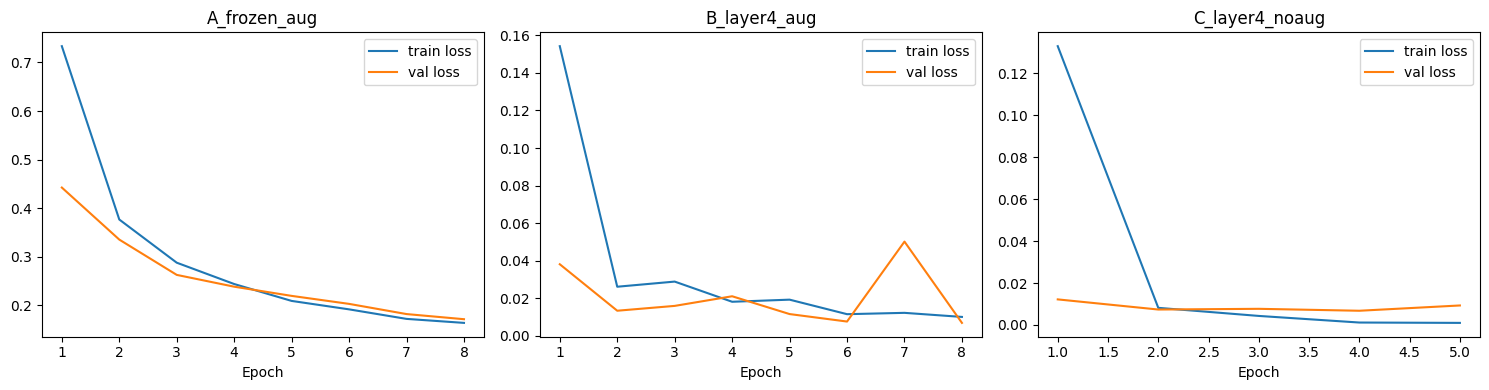

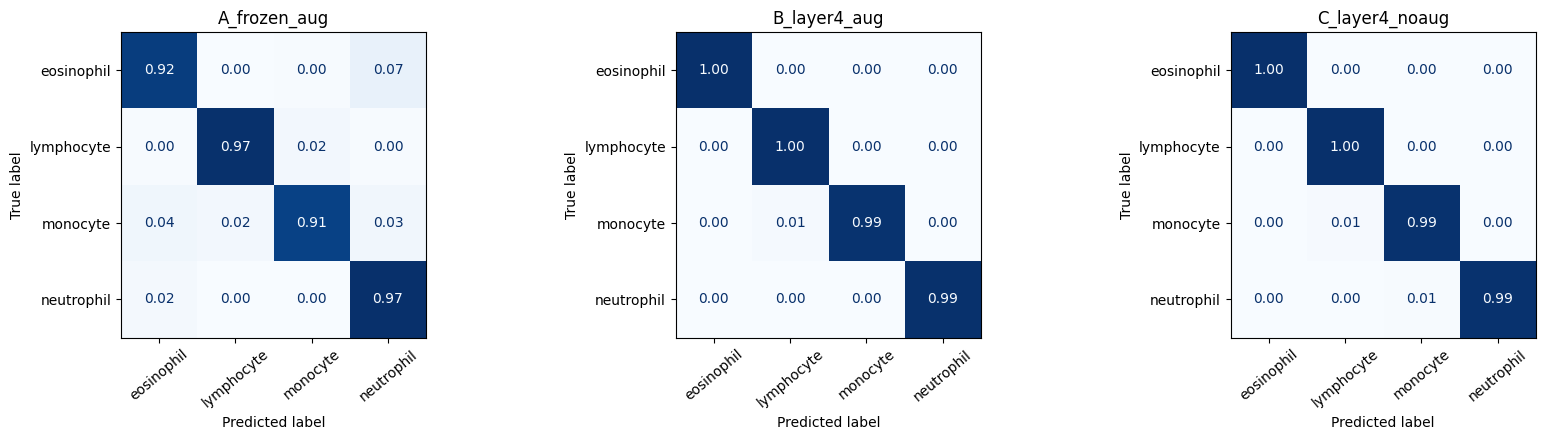

In [7]:
FIG_SEED=SEEDS[0]
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,(name,opts) in zip(axes,EXPERIMENTS.items()):
    h=pd.read_csv(OUT/f'{name}_seed{FIG_SEED}'/'history.csv')
    ax.plot(h.epoch,h.train_loss,label='train loss'); ax.plot(h.epoch,h.val_loss,label='val loss')
    ax.set_title(name); ax.set_xlabel('Epoch'); ax.legend()
plt.tight_layout(); plt.savefig(OUT/'learning_curves.png',dpi=180); plt.show()
fig,axes=plt.subplots(1,3,figsize=(17,4.5))
for ax,name in zip(axes,EXPERIMENTS):
    frame=pd.read_csv(OUT/f'{name}_seed{FIG_SEED}'/'test_predictions.csv')
    cm=confusion_matrix(frame.y_true,frame.y_pred,labels=list(range(4)),normalize='true')
    ConfusionMatrixDisplay(cm,display_labels=CLASSES).plot(ax=ax,cmap='Blues',colorbar=False,values_format='.2f')
    ax.set_title(name); ax.tick_params(axis='x',rotation=40)
plt.tight_layout(); plt.savefig(OUT/'confusion_matrices.png',dpi=180); plt.show()


## 7. Error Examples and Grad-CAM

Use the validation-selected condition and predefined first seed (**42**). Select the first four misclassified and first four correctly classified samples in index order, without cherry-picking heatmaps.

Grad-CAM highlights regions contributing to the **predicted class score**; it does not establish clinically valid reasoning.


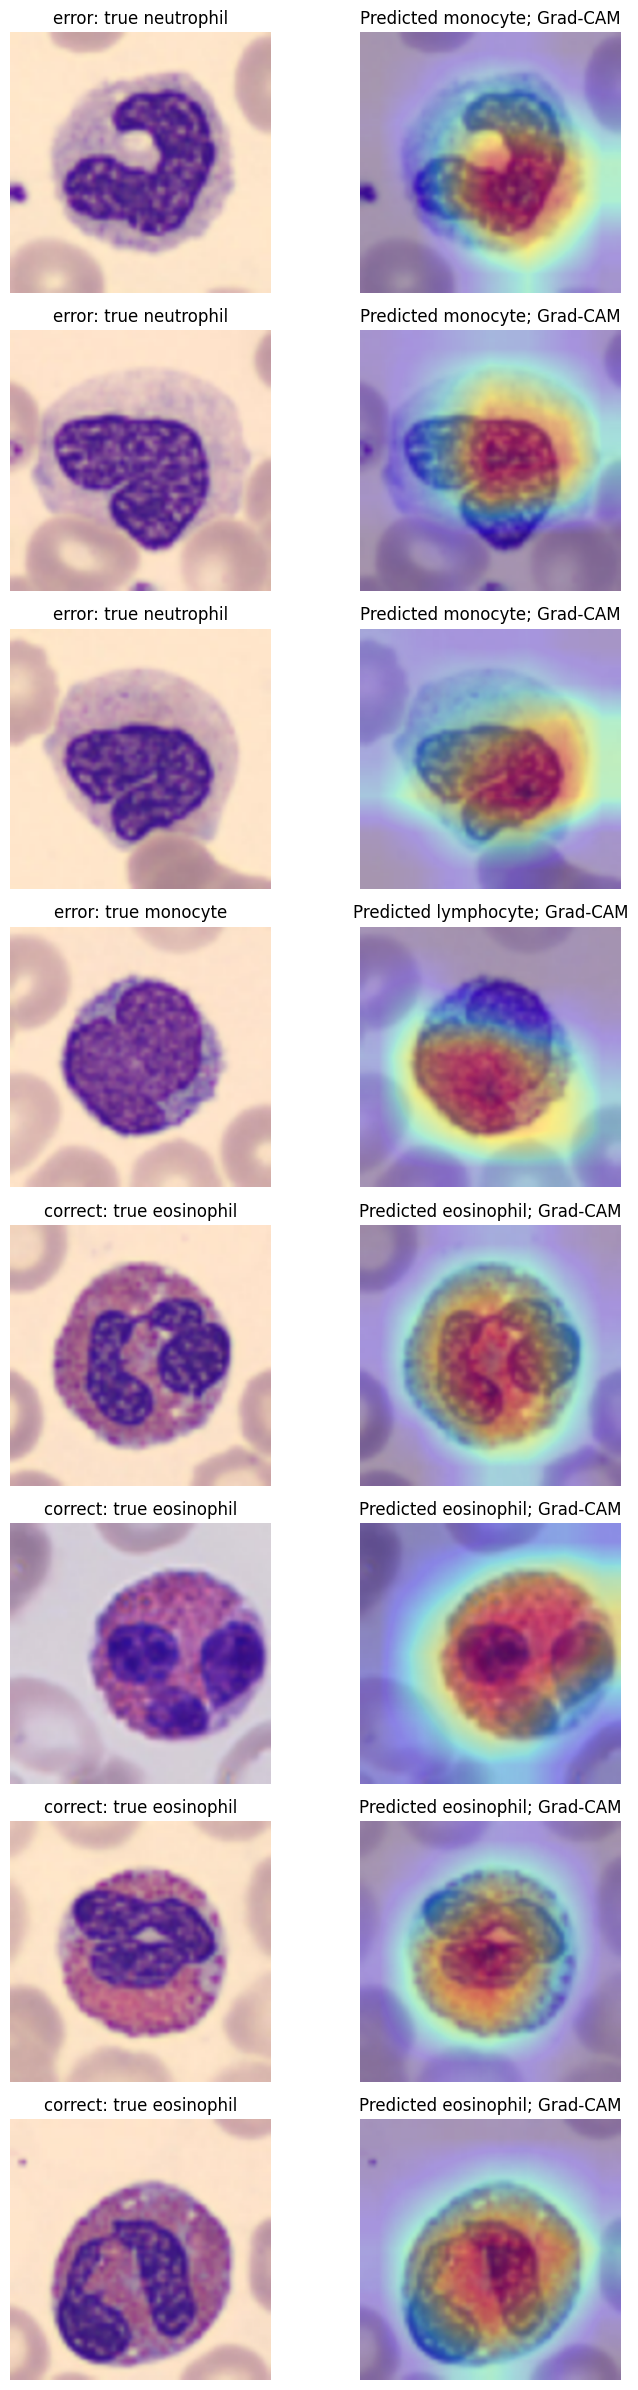

In [8]:
run=OUT/f'{SELECTED}_seed{FIG_SEED}'
model=build_model(EXPERIMENTS[SELECTED]['finetune'],pretrained=False)
model.load_state_dict(torch.load(run/'best.pt',map_location=DEVICE,weights_only=True)); model.eval()
frame=pd.read_csv(run/'test_predictions.csv').sort_values('subset_index')
wrong=frame[frame.y_true!=frame.y_pred].head(4)
right=frame[frame.y_true==frame.y_pred].head(4)
examples=pd.concat([wrong.assign(example_type='error'),right.assign(example_type='correct')])
examples.to_csv(OUT/'visualized_examples.csv',index=False)

def gradcam(model,x,target):
    captured={}
    hook=model.layer4.register_forward_hook(lambda module,inp,out: captured.update(activation=out))
    try:
        logits=model(x)
        act=captured['activation']
        grad=torch.autograd.grad(logits[0,target],act)[0]
        weights=grad.mean(dim=(2,3),keepdim=True)
        heat=(weights*act).sum(1,keepdim=True).relu()
        heat=nn.functional.interpolate(heat,size=x.shape[-2:],mode='bilinear',align_corners=False)[0,0]
        heat=heat.detach().cpu().numpy()
        return (heat-heat.min())/(heat.max()-heat.min()+1e-8)
    finally: hook.remove()

fig,axes=plt.subplots(len(examples),2,figsize=(8,3*len(examples)),squeeze=False)
for row,(_,r) in enumerate(examples.iterrows()):
    idx=int(r.subset_index); im=DATA['test']['images'][idx]
    x=make_transform()(Image.fromarray(im)).unsqueeze(0).to(DEVICE).requires_grad_(True)
    heat=gradcam(model,x,int(r.y_pred))
    im_up=np.asarray(Image.fromarray(im).resize((INPUT_SIZE,INPUT_SIZE)))
    axes[row,0].imshow(im_up); axes[row,1].imshow(im_up)
    axes[row,1].imshow(heat,cmap='jet',alpha=.35,vmin=0,vmax=1)
    axes[row,0].set_title(f'{r.example_type}: true {CLASSES[int(r.y_true)]}')
    axes[row,1].set_title(f'Predicted {CLASSES[int(r.y_pred)]}; Grad-CAM')
    for ax in axes[row]: ax.axis('off')
plt.tight_layout(); plt.savefig(OUT/'error_analysis_gradcam.png',dpi=150); plt.show()


## 8. Forward-Pass States for LecTrace

Capture and save actual intermediate tensors and a four-panel visualization for use in the accompanying LecTrace presentation:

1. **Normalized input:** Resize and normalize the image into a model input tensor.
2. **Final convolutional features:** Extract 512 spatial feature maps. Their channel average is a feature visualization, not Grad-CAM.
3. **Global average pooling:** Average each spatial map to form a 512-dimensional feature vector.
4. **Classification:** Convert logits to softmax probabilities and select the predicted class using argmax.

These outputs support the separate LecTrace script. Resizing does not restore lost detail, and softmax probabilities are not necessarily calibrated.


,shape,min,max
conv_features,"[1, 512, 7, 7]",0.0,11.156097
pooled_features,"[1, 512, 1, 1]",0.0,3.162917
normalized_input,"[1, 3, 224, 224]",-1.685574,2.248908
logits,"[1, 4]",-6.025839,8.747496
probabilities,"[1, 4]",0.0,0.999868
original_image,"[64, 64, 3]",20.0,255.0
true_label,[1],0.0,0.0


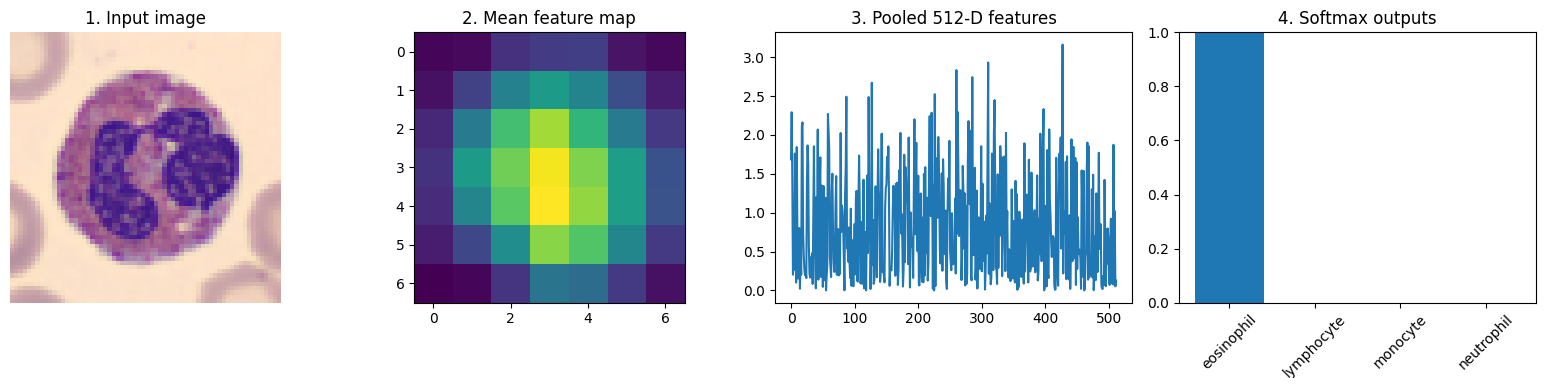

True: eosinophil Predicted: eosinophil


In [9]:
trace_dir=OUT/'trace_states'; trace_dir.mkdir(exist_ok=True)
TRACE_INDEX=0  # fixed example; do not pick only a successful prediction
im=DATA['test']['images'][TRACE_INDEX]
x=make_transform()(Image.fromarray(im)).unsqueeze(0).to(DEVICE)
states={}; hooks=[]
def capture(name):
    def hook(module,inputs,output): states[name]=output.detach().cpu().numpy()
    return hook
hooks.append(model.layer4.register_forward_hook(capture('conv_features')))
hooks.append(model.avgpool.register_forward_hook(capture('pooled_features')))
try:
    with torch.no_grad(): logits=model(x); probabilities=logits.softmax(1)
finally:
    for hook in hooks: hook.remove()
states.update(normalized_input=x.cpu().numpy(),logits=logits.cpu().numpy(),
    probabilities=probabilities.cpu().numpy(),original_image=im,
    true_label=np.array([DATA['test']['labels'][TRACE_INDEX]]))
np.savez_compressed(trace_dir/'forward_states.npz',**states)
description={k:{'shape':list(v.shape),'min':float(v.min()),'max':float(v.max())} for k,v in states.items()}
(trace_dir/'state_shapes.json').write_text(json.dumps(description,indent=2))
display(pd.DataFrame(description).T)
fig,axes=plt.subplots(1,4,figsize=(16,4))
axes[0].imshow(im); axes[0].set_title('1. Input image'); axes[0].axis('off')
axes[1].imshow(states['conv_features'][0].mean(0),cmap='viridis'); axes[1].set_title('2. Mean feature map')
axes[2].plot(states['pooled_features'].reshape(-1)); axes[2].set_title('3. Pooled 512-D features')
axes[3].bar(CLASSES,states['probabilities'][0]); axes[3].set_ylim(0,1)
axes[3].tick_params(axis='x',rotation=45); axes[3].set_title('4. Softmax outputs')
plt.tight_layout(); plt.savefig(trace_dir/'four_states.png',dpi=180); plt.show()
print('True:',CLASSES[int(states['true_label'][0])],
      'Predicted:',CLASSES[int(states['probabilities'][0].argmax())])


## 9. Reporting, References and Export

### Reporting

Describe the Barcelona PBC-derived BloodMNIST+ **four-class subset**, using 64×64 images resized to 224×224. Document the original image-level splits, exact-image deduplication policy (**train → val → test**), exclusion of conflicting labels, and nine removed images.

Final sample counts are **6,349 training, 908 validation, and 1,814 test images**. Report training settings, validation-based selection, and test metrics as **mean ± SD across two seeds**. SD describes training variability, not a confidence interval.

The contribution is a controlled comparison of fine-tuning and augmentation, supported by error analysis. Limitations include one data source, low resolution, four selected classes, unverified patient independence and near-duplicates, and no external validation. Results do not establish disease-diagnostic performance and are not directly comparable with results on other datasets.

### Data and Implementation Sources

- Acevedo et al. (2020). *A dataset of microscopic peripheral blood cell images for development of automatic recognition systems.* https://doi.org/10.1016/j.dib.2020.105474
- Yang et al. (2023). *MedMNIST v2.* https://doi.org/10.1038/s41597-022-01721-8
- MedMNIST data and package: https://medmnist.com/ and https://github.com/MedMNIST/MedMNIST
- He et al. (2016). *Deep Residual Learning for Image Recognition.* https://arxiv.org/abs/1512.03385
- torchvision ResNet18 implementation: https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html
- Selvaraju et al. (2017). *Grad-CAM.* https://arxiv.org/abs/1610.02391

These sources document the data and methods used here; the report requires at least ten relevant references, cited in the body.

### Course Connections and AI Assistance

- **Lecture 2, PDF pp.107–117:** transfer learning, freezing, and fine-tuning.
- **Lecture 2, PDF pp.123–124:** independent samples and correlated images.
- **Lecture 11, PDF pp.30–33:** Grad-CAM.

AI assisted notebook development. The report should describe the assistance received and the checks performed by the authors.

### Export

The exported ZIP contains tables, figures, configurations, training logs, and captured forward-pass states. It excludes dataset files, model weights, and source scripts; checkpoints remain in Google Drive.

For submission, include the executed notebook, LecTrace script and required assets, and report PDF with cover page, alongside the exported results.

In [10]:
handoff={'question':'Does layer4 fine-tuning improve WBC classification, and does augmentation help?',
    'selected_on_validation':SELECTED,'figure_seed':FIG_SEED,'config':CONFIG,
    'remaining_deliverables':['report PDF with cover page','at least 10 verified relevant citations',
        'actual LecTrace Python presentation','executed notebook and supplementary ZIP'],
    'important':'No fabricated or estimated metrics; use only exported actual results.'}
(OUT/'report_handoff.json').write_text(json.dumps(handoff,indent=2))
import zipfile
zip_path=Path('/content/MD6329_WBC_results.zip')
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob('*'):
        if p.is_file() and p.suffix in {'.csv','.json','.png','.npz'}:
            z.write(p,p.relative_to(OUT))
if SAVE_TO_DRIVE: shutil.copy2(zip_path,OUT/'MD6329_WBC_results.zip')
print('Results folder:',OUT)
print('ZIP:',zip_path)
from google.colab import files
files.download(str(zip_path))


Results folder: /content/drive/MyDrive/MD6329_WBC_ResNet18_v2_dedup
ZIP: /content/MD6329_WBC_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. LecTrace Presentation

Build an interactive presentation using the trained model and exported results. No retraining is required.

Run the next four code cells in order to:
1. Install LecTrace.
2. Upload and extract the presentation package.
3. Connect Google Drive and build the presentation.
4. Open the browser preview.

The presentation explains four forward-pass states: **normalized input → convolutional features → global average pooling → classification**, followed by experimental results and error analysis.

In [11]:
import subprocess
import sys

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "lectrace==1.1.30", "numpy", "matplotlib", "pillow"
])

0

In [18]:
from google.colab import files
from pathlib import Path
import zipfile

uploaded = files.upload()
archive_name = next(name for name in uploaded if name.endswith(".zip"))

with zipfile.ZipFile(archive_name) as z:
    z.extractall("/content")

LECTRACE_DIR = Path("/content/MD6329_WBC_LecTrace")
assert (LECTRACE_DIR / "01_wbc_lectrace.py").is_file()

print("Presentation files ready:", LECTRACE_DIR)

Saving WBC_LecTrace.zip to WBC_LecTrace.zip
Presentation files ready: /content/MD6329_WBC_LecTrace


In [19]:
from google.colab import drive
import subprocess

drive.mount("/content/drive")

subprocess.run(
    [
        "lectrace", "build", "01_wbc_lectrace.py",
        "--output", "_site", "--no-incremental"
    ],
    cwd=LECTRACE_DIR,
    check=True
)

print("Presentation built successfully.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Presentation built successfully.


In [20]:
from pathlib import Path
from functools import partial
from http.server import ThreadingHTTPServer, SimpleHTTPRequestHandler
from threading import Thread
from urllib.request import urlopen
from google.colab import output

site_dir = Path("/content/MD6329_WBC_LecTrace/_site")
assert (site_dir / "index.html").is_file(), (
    "Presentation files are missing. Rerun the build cell first."
)

# Stop a previous server created by this cell.
if "wbc_httpd" in globals():
    wbc_httpd.shutdown()
    wbc_httpd.server_close()

# Start a server inside the current notebook runtime.
handler = partial(SimpleHTTPRequestHandler, directory=str(site_dir))
wbc_httpd = ThreadingHTTPServer(("0.0.0.0", 0), handler)
wbc_port = wbc_httpd.server_address[1]

Thread(target=wbc_httpd.serve_forever, daemon=True).start()

# Verify that the presentation is accessible before displaying it.
with urlopen(f"http://127.0.0.1:{wbc_port}/index.html", timeout=5) as response:
    print("Presentation server:", response.status)

output.serve_kernel_port_as_iframe(wbc_port, height=850)

Presentation server: 200


127.0.0.1 - - [23/Oct/2026 15:42:49] "GET /index.html HTTP/1.1" 200 -


<IPython.core.display.Javascript object>

In [21]:
import shutil
from google.colab import files

archive_path = shutil.make_archive(
    "/content/MD6329_WBC_LecTrace_Final",
    "zip",
    root_dir="/content",
    base_dir="MD6329_WBC_LecTrace"
)

files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>